# Kurs CHF/PLN: regresja matematyczna vs sztuczna sieć neuronowa (ANN)

**Cel:** prognoza kursu franka szwajcarskiego na następny dzień roboczy i uczciwe porównanie skuteczności:

| # | Model | Rodzina |
|---|-------|---------|
| 0 | Naiwny: *jutro = dziś* (błądzenie losowe) | punkt odniesienia |
| 1 | Regresja liniowa MNK — liczona **ręcznie z równań normalnych** | regresja |
| 2 | Regresja wielomianowa 2. stopnia + Ridge | regresja |
| 3 | MLP (scikit-learn), zespół 5 sieci | ANN |
| 4 | Sieć 1-warstwowa **napisana od zera w NumPy** (backprop + Adam) | ANN |

**Zasady uczciwego porównania**
* podział chronologiczny: trening → walidacja (dobór hiperparametrów) → test (jedno spojrzenie na końcu),
* skalery i hiperparametry wyznaczane wyłącznie na danych treningowych/walidacyjnych,
* każdy model musi pobić model naiwny — inaczej nie ma wartości prognostycznej,
* istotność różnic: test Diebolda-Mariano, trafność kierunku: test dwumianowy,
* dodatkowo walidacja krocząca (walk-forward) na kilku latach.

**Dane:** średni kurs NBP (tabela A) z API `api.nbp.pl`. Bez dostępu do sieci notebook przełącza się na kursy referencyjne EBC (CHF/PLN wyliczony przez EUR).

In [1]:
import json, os, warnings, urllib.request, urllib.error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf
from scipy import stats
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import TimeSeriesSplit

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# ---------------- konfiguracja ----------------
START      = "2016-01-01"   # po szoku SNB ze stycznia 2015 (zmień, aby go uwzględnić)
END        = pd.Timestamp.today().strftime("%Y-%m-%d")
LAGI       = 10             # ile opóźnionych zwrotów jako cechy
UDZ_TRAIN, UDZ_VAL = 0.70, 0.15   # reszta = test
SEED       = 42
CACHE      = "chf_pln.csv"

# ---------------- styl wykresów ----------------
KOL = {"Rzeczywisty": "#0b0b0b", "Naiwny": "#8a8984", "MNK": "#2a78d6",
       "Wielomian+Ridge": "#eb6834", "MLP (sklearn)": "#1baf7a", "Sieć NumPy": "#6250d6"}
plt.rcParams.update({
    "figure.figsize": (12, 4.5), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "axes.titlecolor": "#0b0b0b", "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 1.8,
    "legend.frameon": False,
})
np.random.seed(SEED)

## 1. Dane

Kolejność źródeł: **cache CSV → API NBP → EBC online → EBC z pakietu `currencyconverter`** (`pip install currencyconverter`, działa offline).
API NBP zwraca maks. 93 dni na zapytanie, więc pobieramy w oknach po 90 dni.

In [2]:
def pobierz_nbp(start, end, waluta="chf"):
    s, e, czesci = pd.Timestamp(start), pd.Timestamp(end), []
    while s <= e:
        k = min(s + pd.Timedelta(days=90), e)
        url = (f"https://api.nbp.pl/api/exchangerates/rates/a/{waluta}/"
               f"{s:%Y-%m-%d}/{k:%Y-%m-%d}/?format=json")
        try:
            with urllib.request.urlopen(url, timeout=15) as r:
                czesci.append(pd.DataFrame(json.load(r)["rates"]))
        except urllib.error.HTTPError as ex:
            if ex.code != 404:      # 404 = brak notowań w danym oknie
                raise
        s = k + pd.Timedelta(days=1)
    df = pd.concat(czesci)
    return pd.Series(df["mid"].values, index=pd.to_datetime(df["effectiveDate"]), name="kurs")

def z_ebc(plik):
    d = pd.read_csv(plik, compression="zip", parse_dates=["Date"]).set_index("Date").sort_index()
    return (d["PLN"] / d["CHF"]).dropna().rename("kurs")   # PLN za 1 CHF

def wczytaj():
    if os.path.exists(CACHE):
        s = pd.read_csv(CACHE, index_col=0, parse_dates=True)["kurs"]
        return s, f"cache ({CACHE})"
    try:
        s = pobierz_nbp(START, END); zrodlo = "NBP, tabela A (kurs średni)"
    except Exception as ex:
        print("NBP niedostępne:", type(ex).__name__)
        try:
            urllib.request.urlretrieve("https://www.ecb.europa.eu/stats/eurofxref/eurofxref-hist.zip", "ecb.zip")
            s = z_ebc("ecb.zip"); zrodlo = "EBC online (kurs krzyżowy przez EUR)"
        except Exception as ex2:
            print("EBC online niedostępny:", type(ex2).__name__)
            import currency_converter
            s = z_ebc(os.path.join(os.path.dirname(currency_converter.__file__), "eurofxref-hist.zip"))
            zrodlo = "EBC z pakietu currencyconverter (kurs krzyżowy przez EUR)"
    s = s.sort_index()
    s = s[~s.index.duplicated()].loc[START:END]
    s.to_frame().to_csv(CACHE)
    return s, zrodlo

kurs, ZRODLO = wczytaj()
print(f"Źródło: {ZRODLO}")
print(f"Zakres: {kurs.index[0]:%Y-%m-%d} → {kurs.index[-1]:%Y-%m-%d}, {len(kurs)} notowań")
kurs.tail()

NBP niedostępne: URLError


EBC online niedostępny: URLError
Źródło: EBC z pakietu currencyconverter (kurs krzyżowy przez EUR)
Zakres: 2016-01-04 → 2026-10-30, 2773 notowań


Date
2026-10-26   4.7645
2026-10-27   4.7646
2026-10-28   4.7632
2026-10-29   4.7645
2026-10-30   4.7899
Name: kurs, dtype: float64

## 2. Eksploracja: dlaczego to trudne zadanie

Kurs walutowy jest niestacjonarny (trend, zmienna wariancja). Modelujemy więc **logarytmiczne zwroty**
$r_t = \ln P_t - \ln P_{t-1}$, które są w przybliżeniu stacjonarne. Prognozę kursu odtwarzamy jako
$\hat P_{t+1} = P_t \cdot e^{\hat r_{t+1}}$.

Kluczowy wykres to autokorelacja zwrotów: jeśli jest bliska zeru, przeszłe zwroty niewiele mówią o jutrze.

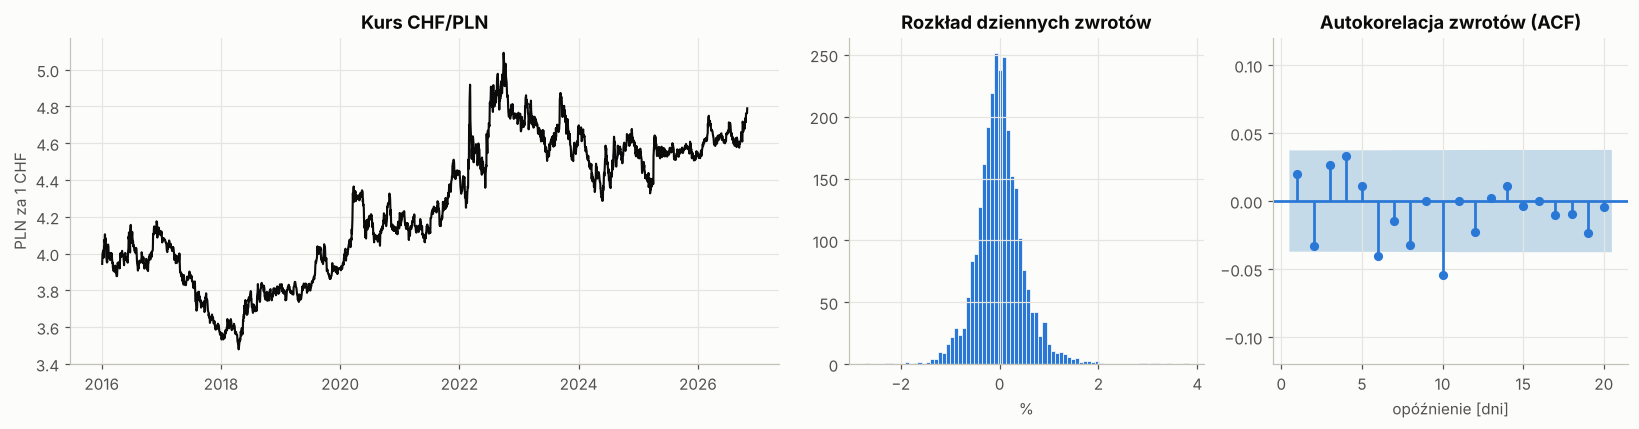

Średni zwrot dzienny: 0.0070%   odch. std.: 0.494%
Kurtoza (nadwyżkowa): 5.45  → grube ogony, rozkład nie jest normalny
Test Ljunga-Boxa (H0: brak autokorelacji):
    lb_stat  lb_pvalue
5    9.3429     0.0961
10  25.6383     0.0043


In [3]:
r = np.log(kurs).diff().dropna()

fig, ax = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [2, 1, 1]})
ax[0].plot(kurs.index, kurs, color=KOL["Rzeczywisty"], lw=1.4)
ax[0].set_title("Kurs CHF/PLN"); ax[0].set_ylabel("PLN za 1 CHF")
ax[1].hist(r * 100, bins=80, color=KOL["MNK"], edgecolor="#fcfcfb", linewidth=0.5)
ax[1].set_title("Rozkład dziennych zwrotów"); ax[1].set_xlabel("%")
plot_acf(r, lags=20, ax=ax[2], zero=False, color=KOL["MNK"], vlines_kwargs={"colors": KOL["MNK"]})
ax[2].set_title("Autokorelacja zwrotów (ACF)"); ax[2].set_xlabel("opóźnienie [dni]"); ax[2].set_ylim(-0.12, 0.12)
plt.tight_layout(); plt.show()

print(f"Średni zwrot dzienny: {r.mean()*100:.4f}%   odch. std.: {r.std()*100:.3f}%")
print(f"Kurtoza (nadwyżkowa): {stats.kurtosis(r):.2f}  → grube ogony, rozkład nie jest normalny")
lb = sm.stats.acorr_ljungbox(r, lags=[5, 10], return_df=True)
print("Test Ljunga-Boxa (H0: brak autokorelacji):"); print(lb)

## 3. Cechy i podział danych

Dla dnia $t$ (znamy wszystko do zamknięcia dnia $t$) budujemy:
* `r_lag1…r_lag10` — zwroty z dni $t, t-1, …, t-9$,
* `ma20` — średnia krocząca zwrotów z 20 dni (momentum),
* `vol20` — zmienność z 20 dni,
* `odch_ma20` — log-odchylenie kursu od jego 20-dniowej średniej (powrót do średniej).

Cel: $y = r_{t+1}$. Żadna cecha nie korzysta z przyszłości.

> Uwaga o współliniowości: średnia z 5 dni (`ma5`) byłaby **dokładną kombinacją liniową** `r_lag1…r_lag5`, więc macierz $X^\top X$
> stałaby się osobliwa i równania normalne nie miałyby jednoznacznego rozwiązania. Dlatego jej nie ma; `ma20` sięga dalej niż lagi, więc jest dopuszczalna.

trening    2016-02-01 → 2023-08-04  (1926 dni)
walidacja  2023-08-07 → 2025-03-18  (413 dni)
test       2025-03-19 → 2026-10-29  (413 dni)


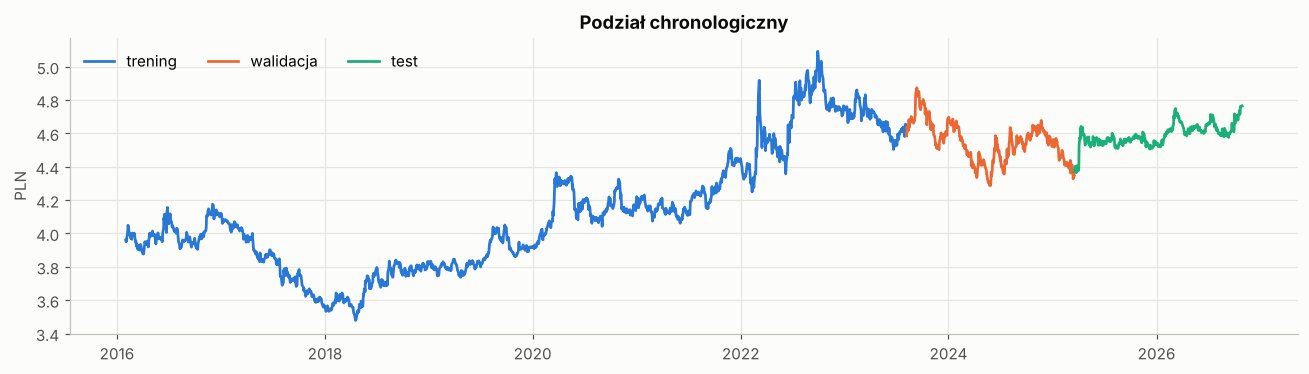

In [4]:
df = pd.DataFrame({"kurs": kurs})
df["r"] = np.log(df["kurs"]).diff()
for k in range(1, LAGI + 1):
    df[f"r_lag{k}"] = df["r"].shift(k - 1)
df["ma20"]      = df["r"].rolling(20).mean()
df["vol20"]     = df["r"].rolling(20).std()
df["odch_ma20"] = np.log(df["kurs"] / df["kurs"].rolling(20).mean())
df["y"]         = df["r"].shift(-1)            # zwrot jutrzejszy
df["kurs_jutro"] = df["kurs"].shift(-1)
df = df.dropna()

CECHY = [f"r_lag{k}" for k in range(1, LAGI + 1)] + ["ma20", "vol20", "odch_ma20"]
n = len(df); i1, i2 = int(n * UDZ_TRAIN), int(n * (UDZ_TRAIN + UDZ_VAL))
tr, va, te = df.iloc[:i1], df.iloc[i1:i2], df.iloc[i2:]

skaler = StandardScaler().fit(tr[CECHY])           # tylko na treningu!
Xtr, Xva, Xte = (skaler.transform(d[CECHY]) for d in (tr, va, te))
ytr, yva, yte = tr["y"].values, va["y"].values, te["y"].values
SIG = ytr.std()                                    # skala celu dla sieci

for nazwa, d in [("trening", tr), ("walidacja", va), ("test", te)]:
    print(f"{nazwa:10s} {d.index[0]:%Y-%m-%d} → {d.index[-1]:%Y-%m-%d}  ({len(d)} dni)")

fig, ax = plt.subplots(figsize=(12, 3.5))
for d, kol, lab in [(tr, KOL["MNK"], "trening"), (va, KOL["Wielomian+Ridge"], "walidacja"), (te, KOL["MLP (sklearn)"], "test")]:
    ax.plot(d.index, d["kurs"], color=kol, label=lab)
ax.set_title("Podział chronologiczny"); ax.set_ylabel("PLN"); ax.legend(ncol=3, loc="upper left")
plt.tight_layout(); plt.show()

## 4. Model 0 — naiwny (błądzenie losowe)

$\hat P_{t+1} = P_t$, czyli $\hat r_{t+1} = 0$. Według hipotezy rynku efektywnego to bardzo trudny przeciwnik.

In [5]:
PRED_VA, PRED_TE = {}, {}
PRED_VA["Naiwny"] = np.zeros(len(va)); PRED_TE["Naiwny"] = np.zeros(len(te))
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
print(f"RMSE zwrotów (walidacja), model naiwny: {rmse(yva, 0)*100:.4f} pp")

RMSE zwrotów (walidacja), model naiwny: 0.5209 pp


## 5. Model 1 — regresja liniowa MNK „od zera”

Model: $y = X\beta + \varepsilon$. Minimalizacja $\lVert y - X\beta\rVert^2$ daje **równania normalne**

$$X^\top X\,\beta = X^\top y \quad\Rightarrow\quad \hat\beta = (X^\top X)^{-1}X^\top y .$$

Rozwiązujemy układ (`np.linalg.solve`) zamiast jawnie odwracać macierz — stabilniej numerycznie — i sprawdzamy zgodność ze scikit-learn.

In [6]:
X1 = np.column_stack([np.ones(len(Xtr)), Xtr])     # kolumna jedynek = wyraz wolny
beta = np.linalg.solve(X1.T @ X1, X1.T @ ytr)

ols_sk = LinearRegression().fit(Xtr, ytr)
print("Zgodność ze sklearn:", np.allclose(beta, np.r_[ols_sk.intercept_, ols_sk.coef_]))

mnk_predict = lambda X: np.column_stack([np.ones(len(X)), X]) @ beta
PRED_VA["MNK"], PRED_TE["MNK"] = mnk_predict(Xva), mnk_predict(Xte)

# Inferencja: które cechy są istotne? (błędy odporne HAC Neweya-Westa)
ols_sm = sm.OLS(ytr, sm.add_constant(pd.DataFrame(Xtr, columns=CECHY))).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
tab = pd.DataFrame({"beta (pp/σ)": ols_sm.params * 100, "p-value": ols_sm.pvalues})
print(f"R² na treningu: {ols_sm.rsquared:.4f}   (F-test p = {ols_sm.f_pvalue:.3f})")
tab.round(4)

Zgodność ze sklearn: True


R² na treningu: 0.0162   (F-test p = 0.027)


,beta (pp/σ),p-value
const,0.0076,0.5058
r_lag1,0.0229,0.4013
r_lag2,-0.0265,0.3030
r_lag3,0.0098,0.7118
r_lag4,0.0166,0.5154
r_lag5,0.0017,0.9403
r_lag6,-0.0160,0.4258
r_lag7,-0.0109,0.5598
r_lag8,-0.0301,0.0959
r_lag9,0.0152,0.3859


## 6. Model 2 — regresja wielomianowa 2. stopnia + Ridge

Dodajemy kwadraty i iloczyny cech (nieliniowość „klasycznymi” środkami) — przy 13 cechach to 104 kolumny,
więc potrzebna jest regularyzacja L2: $\min_\beta \lVert y - X\beta\rVert^2 + \alpha\lVert\beta\rVert^2$.
Siłę $\alpha$ dobieramy na zbiorze walidacyjnym.

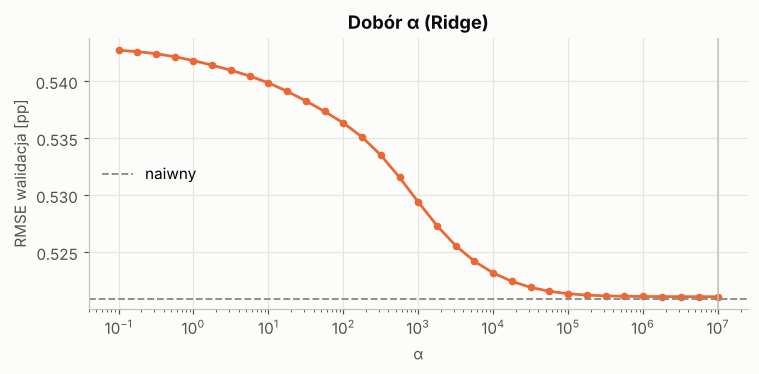

Wybrane α = 10,000,000.0   liczba cech po rozszerzeniu: 104
Norma współczynników: 8.12e-07  (duże α ⇒ model ściągnięty prawie do stałej = średniego zwrotu)


In [7]:
poly = PolynomialFeatures(degree=2, include_bias=False).fit(Xtr)
Ptr, Pva, Pte = poly.transform(Xtr), poly.transform(Xva), poly.transform(Xte)

alfy = np.logspace(-1, 7, 33)
wyn = [rmse(yva, Ridge(alpha=a).fit(Ptr, ytr).predict(Pva)) for a in alfy]
ALFA = alfy[int(np.argmin(wyn))]
ridge = Ridge(alpha=ALFA).fit(Ptr, ytr)
PRED_VA["Wielomian+Ridge"], PRED_TE["Wielomian+Ridge"] = ridge.predict(Pva), ridge.predict(Pte)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogx(alfy, np.array(wyn) * 100, color=KOL["Wielomian+Ridge"], marker="o", ms=4)
ax.axhline(rmse(yva, 0) * 100, color=KOL["Naiwny"], ls="--", lw=1.2, label="naiwny")
ax.axvline(ALFA, color="#c3c2b7", lw=1)
ax.set_xlabel("α"); ax.set_ylabel("RMSE walidacja [pp]"); ax.set_title("Dobór α (Ridge)"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Wybrane α = {ALFA:,.1f}   liczba cech po rozszerzeniu: {Ptr.shape[1]}")
print(f"Norma współczynników: {np.linalg.norm(ridge.coef_):.2e}  (duże α ⇒ model ściągnięty prawie do stałej = średniego zwrotu)")

## 7. Model 3 — sieć MLP (scikit-learn)

Wielowarstwowy perceptron z aktywacją ReLU, optymalizatorem Adam i wczesnym zatrzymaniem.
Cel skalujemy przez $\sigma_y$ (zwroty rzędu 0,3% to zbyt małe liczby dla wygodnego treningu).
Architekturę i regularyzację wybieramy na walidacji, a następnie uśredniamy **5 sieci z różnymi ziarnami** —
pojedyncza sieć na tak zaszumionych danych ma dużą wariancję.

In [8]:
def mlp(hidden, alpha, seed):
    return MLPRegressor(hidden_layer_sizes=hidden, alpha=alpha, learning_rate_init=1e-3,
                        max_iter=500, early_stopping=True, validation_fraction=0.15,
                        n_iter_no_change=20, random_state=seed)

siatka = [(h, a) for h in [(8,), (32,), (32, 16), (64, 32)] for a in [1e-3, 1e-1, 1.0, 10.0]]
wyniki = []
for h, a in siatka:
    p = np.mean([mlp(h, a, s).fit(Xtr, ytr / SIG).predict(Xva) for s in range(3)], axis=0) * SIG
    wyniki.append({"warstwy": str(h), "alpha": a, "RMSE_val_pp": rmse(yva, p) * 100})
siatka_df = pd.DataFrame(wyniki).sort_values("RMSE_val_pp")
NAJ = siatka[int(pd.DataFrame(wyniki)["RMSE_val_pp"].idxmin())]
print(f"Najlepsza konfiguracja: warstwy={NAJ[0]}, alpha={NAJ[1]}   (naiwny: {rmse(yva,0)*100:.4f} pp)")
display(siatka_df.head(6))

zespol = [mlp(*NAJ, SEED + s).fit(Xtr, ytr / SIG) for s in range(5)]
mlp_predict = lambda X: np.mean([m.predict(X) for m in zespol], axis=0) * SIG
PRED_VA["MLP (sklearn)"], PRED_TE["MLP (sklearn)"] = mlp_predict(Xva), mlp_predict(Xte)

Najlepsza konfiguracja: warstwy=(32, 16), alpha=10.0   (naiwny: 0.5209 pp)


,warstwy,alpha,RMSE_val_pp
11,"(32, 16)",10.0000,0.5203
3,"(8,)",10.0000,0.5206
7,"(32,)",10.0000,0.5208
14,"(64, 32)",1.0000,0.5216
15,"(64, 32)",10.0000,0.5217
10,"(32, 16)",1.0000,0.5220


## 8. Model 4 — sieć neuronowa od zera (NumPy)

Jedna warstwa ukryta $H$ neuronów z $\tanh$:

$$\mathbf a = \tanh(\mathbf x W_1 + \mathbf b_1), \qquad \hat y = \mathbf a W_2 + b_2$$

Funkcja straty: MSE + kara L2. Gradienty z reguły łańcuchowej (wsteczna propagacja):

$$\delta_2 = \tfrac{2}{m}(\hat y - y),\quad \nabla W_2 = \mathbf a^\top\delta_2,\quad
\delta_1 = (\delta_2 W_2^\top)\odot(1-\mathbf a^2),\quad \nabla W_1 = \mathbf x^\top\delta_1 .$$

Aktualizacja wag: Adam; wczesne zatrzymanie na zbiorze walidacyjnym.

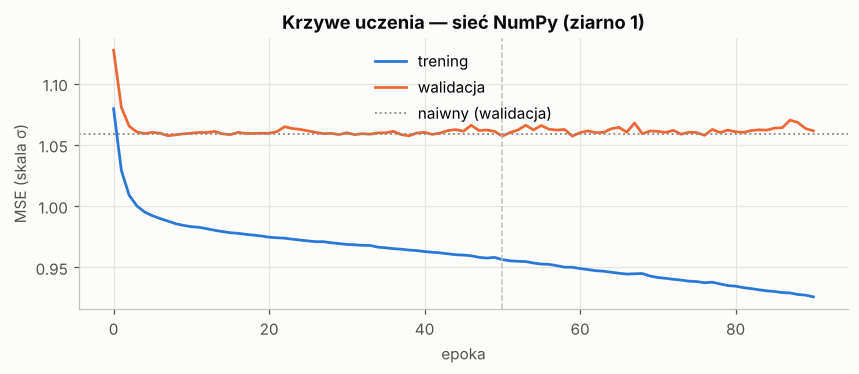

Epoki do wczesnego zatrzymania: [50, 86, 61, 57, 96]


In [9]:
class SiecNumpy:
    def __init__(self, n_in, H=16, lr=1e-3, l2=1e-3, seed=0):
        g = np.random.default_rng(seed)
        self.p = [g.normal(0, np.sqrt(1 / n_in), (n_in, H)), np.zeros(H),
                  g.normal(0, np.sqrt(1 / H), (H, 1)), np.zeros(1)]
        self.lr, self.l2, self.g = lr, l2, g

    def forward(self, X):
        W1, b1, W2, b2 = self.p
        A = np.tanh(X @ W1 + b1)
        return (A @ W2 + b2).ravel(), A

    def predict(self, X):
        return self.forward(X)[0]

    def grad(self, X, y):
        W1, b1, W2, b2 = self.p
        out, A = self.forward(X)
        d2 = (2 / len(y)) * (out - y)[:, None]
        d1 = (d2 @ W2.T) * (1 - A ** 2)
        return [X.T @ d1 + self.l2 * W1, d1.sum(0), A.T @ d2 + self.l2 * W2, d2.sum(0)]

    def fit(self, X, y, Xv, yv, epoki=400, batch=64, cierpliwosc=40):
        m = [np.zeros_like(w) for w in self.p]; v = [np.zeros_like(w) for w in self.p]
        b1, b2, eps, t = 0.9, 0.999, 1e-8, 0
        self.hist, naj, best, czekaj = {"train": [], "val": []}, np.inf, None, 0
        for ep in range(epoki):
            idx = self.g.permutation(len(X))
            for s in range(0, len(X), batch):
                j = idx[s:s + batch]; t += 1
                for k, gk in enumerate(self.grad(X[j], y[j])):          # Adam
                    m[k] = b1 * m[k] + (1 - b1) * gk
                    v[k] = b2 * v[k] + (1 - b2) * gk ** 2
                    self.p[k] -= self.lr * (m[k] / (1 - b1 ** t)) / (np.sqrt(v[k] / (1 - b2 ** t)) + eps)
            lt, lv = np.mean((self.predict(X) - y) ** 2), np.mean((self.predict(Xv) - yv) ** 2)
            self.hist["train"].append(lt); self.hist["val"].append(lv)
            if lv < naj - 1e-6: naj, best, czekaj = lv, [w.copy() for w in self.p], 0
            else:
                czekaj += 1
                if czekaj >= cierpliwosc: break
        self.p, self.best_epoch = best, int(np.argmin(self.hist["val"]))
        return self

sieci = [SiecNumpy(Xtr.shape[1], H=16, l2=1e-2, seed=SEED + s).fit(Xtr, ytr / SIG, Xva, yva / SIG) for s in range(5)]
np_predict = lambda X: np.mean([s.predict(X) for s in sieci], axis=0) * SIG
PRED_VA["Sieć NumPy"], PRED_TE["Sieć NumPy"] = np_predict(Xva), np_predict(Xte)

h = sieci[0].hist
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(h["train"], color=KOL["MNK"], label="trening")
ax.plot(h["val"], color=KOL["Wielomian+Ridge"], label="walidacja")
ax.axvline(sieci[0].best_epoch, color="#c3c2b7", lw=1, ls="--")
ax.axhline(np.mean((yva / SIG) ** 2), color=KOL["Naiwny"], lw=1.2, ls=":", label="naiwny (walidacja)")
ax.set_xlabel("epoka"); ax.set_ylabel("MSE (skala σ)"); ax.set_title("Krzywe uczenia — sieć NumPy (ziarno 1)"); ax.legend()
plt.tight_layout(); plt.show()
print("Epoki do wczesnego zatrzymania:", [s.best_epoch for s in sieci])

## 9. Porównanie skuteczności na zbiorze testowym

Metryki:
* **MAE / RMSE** prognozy kursu (w groszach),
* **MAPE** — średni procentowy błąd kursu,
* **R² OOS** — $1 - \sum(y-\hat y)^2 / \sum y^2$ względem modelu naiwnego (>0 = lepiej niż naiwny),
* **Trafność kierunku** — czy model przewidział wzrost/spadek (+ test dwumianowy vs 50%),
* **Test Diebolda-Mariano** — czy różnica kwadratów błędów względem modelu naiwnego jest istotna statystycznie.

In [10]:
def test_dm(e1, e2, h=1):
    # H0: równa dokładność. d<0 → model 1 lepszy.
    d = e1 ** 2 - e2 ** 2; T = len(d); dc = d - d.mean()
    gamma = [np.sum(dc[k:] * dc[:T - k]) / T for k in range(h)]
    var = (gamma[0] + 2 * sum(gamma[1:])) / T
    dm = d.mean() / np.sqrt(var)
    return dm, 2 * stats.norm.sf(abs(dm))

def ocena(y, pred, P_t, P_next):
    wiersze = []
    for nazwa, rh in pred.items():
        p_hat = P_t * np.exp(rh); e = P_next - p_hat
        w = {"model": nazwa, "MAE [gr]": np.mean(np.abs(e)) * 100, "RMSE [gr]": np.sqrt(np.mean(e ** 2)) * 100,
             "MAPE [%]": np.mean(np.abs(e / P_next)) * 100,
             "R² OOS [%]": (1 - np.sum((y - rh) ** 2) / np.sum(y ** 2)) * 100}
        maska = (y != 0) & (rh != 0)
        if maska.sum() > 0 and nazwa != "Naiwny":
            traf = np.sign(y[maska]) == np.sign(rh[maska])
            w["Trafność kier. [%]"] = traf.mean() * 100
            w["p (dwumianowy)"] = stats.binomtest(traf.sum(), maska.sum(), 0.5).pvalue
            w["DM"], w["p (DM)"] = test_dm(y - rh, y)
        wiersze.append(w)
    return pd.DataFrame(wiersze).set_index("model")

wyniki_val  = ocena(yva, PRED_VA, va["kurs"].values, va["kurs_jutro"].values)
wyniki_test = ocena(yte, PRED_TE, te["kurs"].values, te["kurs_jutro"].values)
print("WALIDACJA"); display(wyniki_val.round(4))
print("TEST (wynik końcowy)"); display(wyniki_test.round(4))

WALIDACJA


,MAE [gr],RMSE [gr],MAPE [%],R² OOS [%],Trafność kier. [%],p (dwumianowy),DM,p (DM)
model,,,,,,,,
Naiwny,1.7873,2.3701,0.3929,0.0000,NaN,NaN,NaN,NaN
MNK,1.7924,2.3718,0.3940,-0.0972,53.0266,0.2376,0.0760,0.9394
Wielomian+Ridge,1.7890,2.3712,0.3933,-0.0872,47.9419,0.4311,0.6045,0.5455
MLP (sklearn),1.7854,2.3664,0.3925,0.3446,52.5424,0.3251,-0.9388,0.3478
Sieć NumPy,1.7825,2.3517,0.3918,1.6198,56.1743,0.0138,-1.2697,0.2042


TEST (wynik końcowy)


,MAE [gr],RMSE [gr],MAPE [%],R² OOS [%],Trafność kier. [%],p (dwumianowy),DM,p (DM)
model,,,,,,,,
Naiwny,1.2158,1.7773,0.2646,0.0000,NaN,NaN,NaN,NaN
MNK,1.2428,1.8176,0.2705,-4.5637,45.5206,0.0764,2.7260,0.0064
Wielomian+Ridge,1.2168,1.7758,0.2648,0.1766,49.3947,0.8440,-0.9109,0.3623
MLP (sklearn),1.2220,1.7846,0.2659,-0.8071,47.6998,0.3758,1.5023,0.1330
Sieć NumPy,1.2498,1.8282,0.2720,-5.7941,46.4891,0.1682,3.1399,0.0017


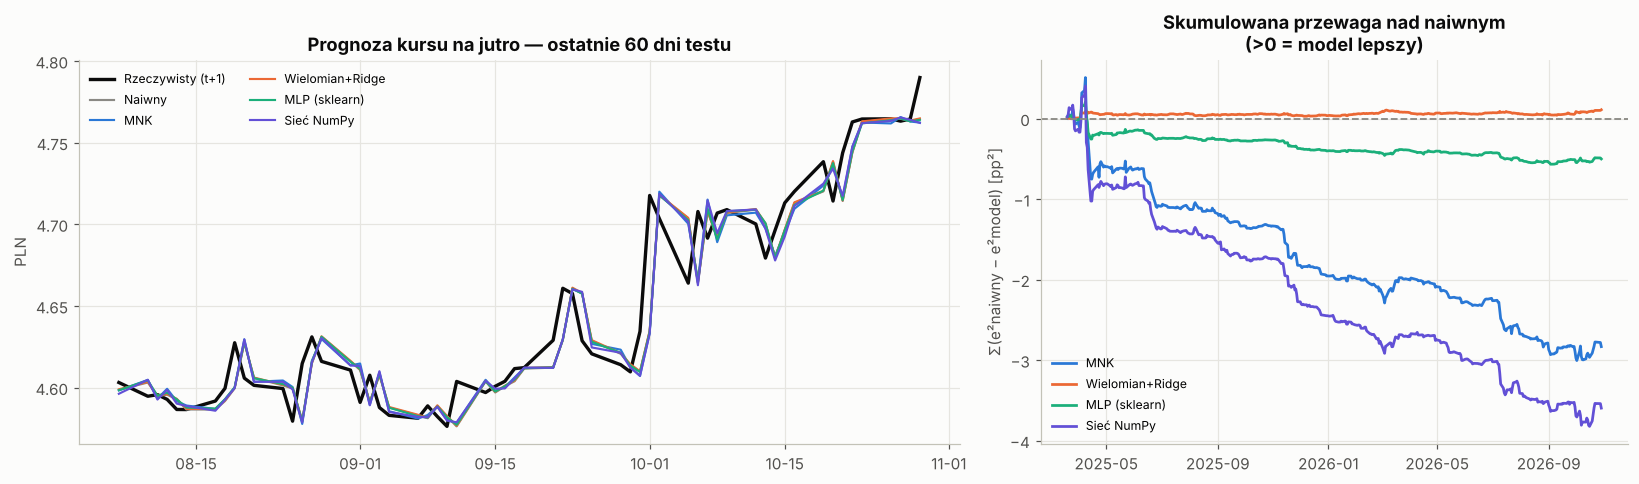

In [11]:
MODELE = [m for m in PRED_TE if m != "Naiwny"]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [3, 2]})

# a) ostatnie 60 dni: kurs vs prognozy
ost = te.iloc[-60:]; d = ost.index
ax[0].plot(d, ost["kurs_jutro"], color=KOL["Rzeczywisty"], lw=2.2, label="Rzeczywisty (t+1)")
for mdl in ["Naiwny"] + MODELE:
    ax[0].plot(d, ost["kurs"] * np.exp(PRED_TE[mdl][-60:]), color=KOL[mdl], lw=1.4, label=mdl)
ax[0].set_title("Prognoza kursu na jutro — ostatnie 60 dni testu"); ax[0].set_ylabel("PLN"); ax[0].legend(fontsize=8, ncol=2)

# b) skumulowana przewaga nad modelem naiwnym
for mdl in MODELE:
    przewaga = np.cumsum(yte ** 2 - (yte - PRED_TE[mdl]) ** 2) * 1e4
    ax[1].plot(te.index, przewaga, color=KOL[mdl], label=mdl)
ax[1].axhline(0, color=KOL["Naiwny"], lw=1.2, ls="--")
ax[1].set_title("Skumulowana przewaga nad naiwnym\n(>0 = model lepszy)"); ax[1].set_ylabel("Σ(e²naiwny − e²model) [pp²]")
ax[1].legend(fontsize=8)
ax[1].xaxis.set_major_locator(mdates.MonthLocator(interval=4)); ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
plt.tight_layout(); plt.show()

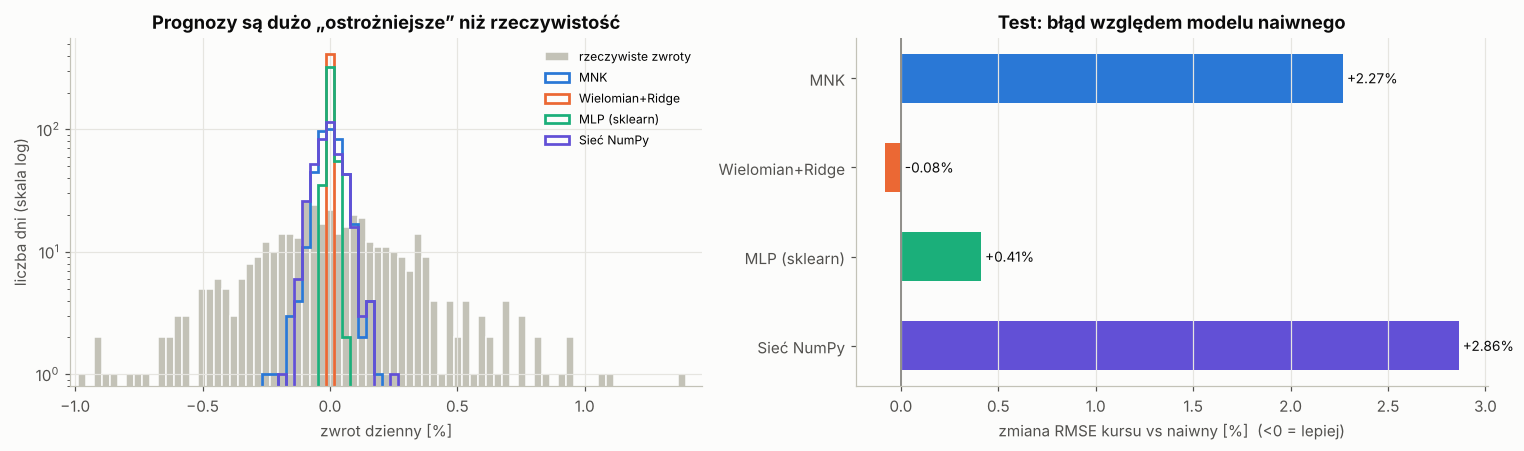

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
# a) jak duże są prognozowane zwroty w porównaniu z rzeczywistymi
biny = np.linspace(*np.percentile(yte * 100, [0.5, 99.5]), 80)
cnt, _, _ = ax[0].hist(yte * 100, bins=biny, color="#c3c2b7", edgecolor="#fcfcfb", label="rzeczywiste zwroty")
for mdl in MODELE:
    ax[0].hist(PRED_TE[mdl] * 100, bins=biny, histtype="step", lw=1.8, color=KOL[mdl], label=mdl)
ax[0].set_yscale("log"); ax[0].set_ylim(0.8, None); ax[0].set_ylabel("liczba dni (skala log)")
ax[0].set_xlim(np.percentile(yte * 100, [0.5, 99.5])); ax[0].set_xlabel("zwrot dzienny [%]")
ax[0].set_title("Prognozy są dużo „ostrożniejsze” niż rzeczywistość"); ax[0].legend(fontsize=8)

# b) RMSE względem naiwnego
rel = (wyniki_test["RMSE [gr]"] / wyniki_test.loc["Naiwny", "RMSE [gr]"] - 1) * 100
rel = rel.drop("Naiwny")
bars = ax[1].barh(rel.index, rel.values, color=[KOL[m] for m in rel.index], height=0.55)
ax[1].axvline(0, color=KOL["Naiwny"], lw=1.2)
for b, v in zip(bars, rel.values):
    ax[1].text(max(v, 0), b.get_y() + b.get_height() / 2, f" {v:+.2f}%", va="center",
               ha="left", color="#0b0b0b", fontsize=9)
ax[1].set_xlabel("zmiana RMSE kursu vs naiwny [%]  (<0 = lepiej)"); ax[1].set_title("Test: błąd względem modelu naiwnego")
ax[1].invert_yaxis(); ax[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 10. Walidacja krocząca (walk-forward)

Jeden zbiór testowy to jeden „scenariusz rynkowy”. Sprawdzamy stabilność wyniku: 6 kolejnych okien testowych po ~250 dni,
każdy model trenowany od nowa na wszystkich wcześniejszych danych (hiperparametry jak wyżej).

,model,MLP (sklearn),MNK,Sieć NumPy,Wielomian+Ridge
okno,od,,,,
1,2020-12,0.0400,0.3500,1.2000,-0.0600
2,2021-12,0.3500,1.1400,1.3800,-0.0200
3,2022-11,0.0200,0.6700,1.1900,0.1000
4,2023-11,-0.2500,-0.4500,-0.1500,-0.0200
5,2024-11,0.3300,1.3900,1.4400,0.0400
6,2025-11,0.6500,1.6800,2.0100,-0.0800


Liczba okien, w których model pobił naiwny:
model
MLP (sklearn)      1
MNK                1
Sieć NumPy         1
Wielomian+Ridge    4
dtype: int64


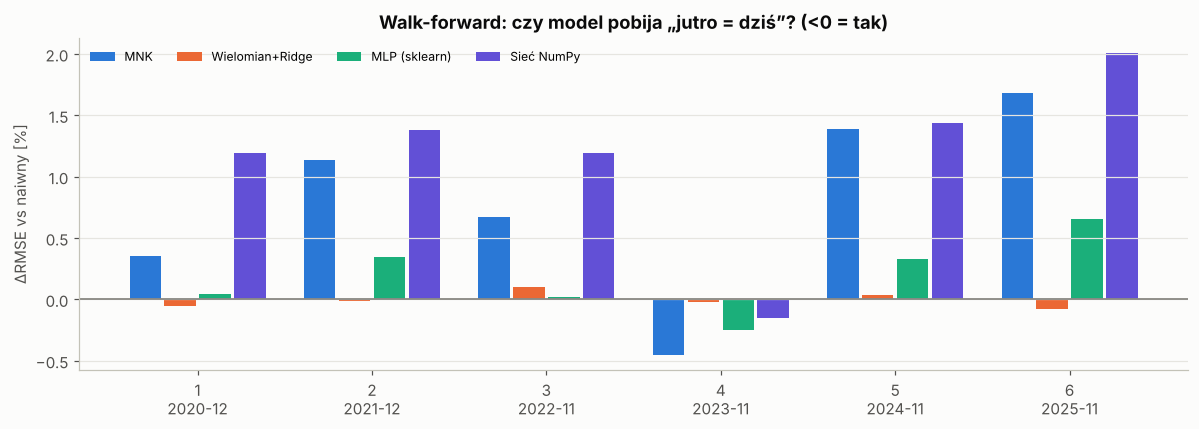

In [13]:
X_all, y_all = df[CECHY].values, df["y"].values
P_t_all, P_n_all = df["kurs"].values, df["kurs_jutro"].values
tss = TimeSeriesSplit(n_splits=6, test_size=250)
wf = []
for f, (itr, ite) in enumerate(tss.split(X_all), 1):
    sk = StandardScaler().fit(X_all[itr]); A, B = sk.transform(X_all[itr]), sk.transform(X_all[ite])
    ya, yb, sg = y_all[itr], y_all[ite], y_all[itr].std()
    pf = PolynomialFeatures(2, include_bias=False).fit(A)
    nv = int(len(A) * 0.85)
    preds = {
        "MNK": LinearRegression().fit(A, ya).predict(B),
        "Wielomian+Ridge": Ridge(alpha=ALFA).fit(pf.transform(A), ya).predict(pf.transform(B)),
        "MLP (sklearn)": np.mean([mlp(*NAJ, s).fit(A, ya / sg).predict(B) for s in range(3)], axis=0) * sg,
        "Sieć NumPy": np.mean([SiecNumpy(A.shape[1], 16, l2=1e-2, seed=s).fit(A[:nv], ya[:nv] / sg, A[nv:], ya[nv:] / sg).predict(B)
                               for s in range(3)], axis=0) * sg,
    }
    e_n = P_n_all[ite] - P_t_all[ite]
    for mdl, rh in preds.items():
        e = P_n_all[ite] - P_t_all[ite] * np.exp(rh)
        wf.append({"okno": f, "od": df.index[ite[0]].strftime("%Y-%m"), "model": mdl,
                   "ΔRMSE vs naiwny [%]": (np.sqrt(np.mean(e**2)) / np.sqrt(np.mean(e_n**2)) - 1) * 100,
                   "p (DM)": test_dm(yb - rh, yb)[1]})
wf = pd.DataFrame(wf)
tab_wf = wf.pivot(index=["okno", "od"], columns="model", values="ΔRMSE vs naiwny [%]")
display(tab_wf.round(2))
print("Liczba okien, w których model pobił naiwny:"); print((tab_wf < 0).sum())

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(tab_wf)); szer = 0.2
for k, mdl in enumerate(MODELE):
    ax.bar(x + (k - 1.5) * szer, tab_wf[mdl], width=szer - 0.02, color=KOL[mdl], label=mdl)
ax.axhline(0, color=KOL["Naiwny"], lw=1.2)
ax.set_xticks(x, [f"{o}\n{d}" for o, d in tab_wf.index]); ax.set_ylabel("ΔRMSE vs naiwny [%]")
ax.set_title("Walk-forward: czy model pobija „jutro = dziś”? (<0 = tak)"); ax.legend(ncol=4, fontsize=8)
ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()

## 11. Pułapka: modelowanie poziomu kursu i „rewelacyjne” R²

Częsty błąd w tutorialach: regresja/sieć na **poziomach** kursu ($P_{t-9}…P_t \to P_{t+1}$).
R² wychodzi wysokie (0,9+) i wykres prognozy „idealnie” pokrywa się z rzeczywistością — ale model naiwny osiąga to samo,
bo prognoza to w praktyce przesunięty o dzień wczorajszy kurs. Dodatkowo MLP na poziomach nie potrafi ekstrapolować poza zakres kursów z treningu.

In [14]:
L = pd.concat({f"P_lag{k}": df["kurs"].shift(k - 1) for k in range(1, LAGI + 1)}, axis=1)
Lp = pd.concat([L, df["kurs_jutro"]], axis=1).dropna()
Ltr, Lte = Lp.loc[tr.index.intersection(Lp.index)], Lp.loc[te.index]
cols = list(L.columns)

lin_lvl = LinearRegression().fit(Ltr[cols], Ltr["kurs_jutro"])
sx, sy = StandardScaler().fit(Ltr[cols]), StandardScaler().fit(Ltr[["kurs_jutro"]])
mlp_lvl = mlp((32, 16), 1e-3, SEED).fit(sx.transform(Ltr[cols]), sy.transform(Ltr[["kurs_jutro"]]).ravel())

y_lvl = Lte["kurs_jutro"].values
kand = {"Naiwny": Lte["P_lag1"].values,
        "MNK na poziomach": lin_lvl.predict(Lte[cols]),
        "MLP na poziomach": sy.inverse_transform(mlp_lvl.predict(sx.transform(Lte[cols]))[:, None]).ravel()}
r2 = lambda y, p: 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)
pd.DataFrame({m: {"R² (poziomy)": r2(y_lvl, p), "RMSE [gr]": rmse(y_lvl, p) * 100} for m, p in kand.items()}).T.round(4)

,R² (poziomy),RMSE [gr]
Naiwny,0.9279,1.7773
MNK na poziomach,0.9245,1.8182
MLP na poziomach,0.8968,2.1258


## 12. Podsumowanie (liczone automatycznie)

In [15]:
t = wyniki_test
naiwny = t.loc["Naiwny", "RMSE [gr]"]
print(f"Źródło danych: {ZRODLO};  test: {te.index[0]:%Y-%m-%d} → {te.index[-1]:%Y-%m-%d}\n")
for m in MODELE:
    zm = (t.loc[m, "RMSE [gr]"] / naiwny - 1) * 100
    ist = "istotna" if t.loc[m, "p (DM)"] < 0.05 else "nieistotna"
    print(f"{m:16s} RMSE {t.loc[m,'RMSE [gr]']:.3f} gr ({zm:+.2f}% vs naiwny, różnica {ist}, p={t.loc[m,'p (DM)']:.2f}); "
          f"kierunek {t.loc[m,'Trafność kier. [%]']:.1f}% (p={t.loc[m,'p (dwumianowy)']:.2f})")
print(f"\nNaiwny          RMSE {naiwny:.3f} gr")
reg, ann = t.loc[["MNK", "Wielomian+Ridge"], "RMSE [gr]"].min(), t.loc[["MLP (sklearn)", "Sieć NumPy"], "RMSE [gr]"].min()
print(f"\nNajlepsza regresja: {reg:.3f} gr   |   najlepsza ANN: {ann:.3f} gr   →  "
      f"{'ANN' if ann < reg else 'regresja'} lepsza o {abs(reg - ann) / max(reg, ann) * 100:.2f}%")

Źródło danych: EBC z pakietu currencyconverter (kurs krzyżowy przez EUR);  test: 2025-03-19 → 2026-10-29

MNK              RMSE 1.818 gr (+2.27% vs naiwny, różnica istotna, p=0.01); kierunek 45.5% (p=0.08)
Wielomian+Ridge  RMSE 1.776 gr (-0.08% vs naiwny, różnica nieistotna, p=0.36); kierunek 49.4% (p=0.84)
MLP (sklearn)    RMSE 1.785 gr (+0.41% vs naiwny, różnica nieistotna, p=0.13); kierunek 47.7% (p=0.38)
Sieć NumPy       RMSE 1.828 gr (+2.86% vs naiwny, różnica istotna, p=0.00); kierunek 46.5% (p=0.17)

Naiwny          RMSE 1.777 gr

Najlepsza regresja: 1.776 gr   |   najlepsza ANN: 1.785 gr   →  regresja lepsza o 0.49%


### Wnioski

Przebieg referencyjny: dane EBC do 30.10.2026, test 19.03.2025 – 29.10.2026. Po pobraniu danych z NBP liczby mogą się nieznacznie różnić, a komórka powyżej przelicza je na nowo.

1. **Żaden model nie pobił istotnie modelu „jutro = dziś”.** Najlepszy wynik testowy (Wielomian+Ridge, −0,08% RMSE) jest nieistotny (DM p≈0,36). Do tego α wylądowało na górnej granicy siatki, czyli model zredukował się do stałej, średniego dryfu. Nie wykorzystuje więc żadnej cechy.
2. **Złożoność szkodzi.** MNK (+2,3%) i sieć NumPy (+2,9%) są *istotnie gorsze* od naiwnego (p<0,01): dopasowały szum. R² na treningu wynosi 1,6%. Test Ljunga-Boxa wykrywa słabą autokorelację w całej próbie, ale jest ona niestabilna w czasie i nie przenosi się na przyszłość.
3. **Regularyzacja „wyłącza” modele i to jest diagnoza.** I Ridge, i MLP wybrały najsilniejszą karę z siatki (MLP: alpha=10). Gdy optymalny model to model ściągnięty do zera, w cechach nie ma użytecznej informacji o jutrzejszym zwrocie.
4. **Walidacja ≠ test.** Sieć NumPy była najlepsza na walidacji (RMSE −0,8%, trafność kierunku 56%, p≈0,01), a na teście wypadła najgorzej. Ten sam zbiór walidacyjny służył do wczesnego zatrzymania, więc jej wynik walidacyjny jest optymistycznie obciążony. Stąd osobny test i walk-forward.
5. **Regresja vs ANN: remis na poziomie szumu.** Na samych przeszłych kursach sieć nie ma czego „nieliniowo” wychwycić. Różnice między najlepszą regresją a najlepszą ANN to dziesiąte części procenta. W walk-forward tylko model sprowadzony do stałej (Ridge) bywa minimalnie lepszy od naiwnego (4 z 6 okien, różnice ~0,05%).
6. **Trafność kierunku poniżej 50%** u wszystkich modeli na teście: zero przewagi informacyjnej.
7. **Pułapka R² na poziomach:** model naiwny ma R²≈0,93. Wysokie R² prognozy kursu o niczym nie świadczy, a MLP na poziomach był najgorszy (RMSE +20%).

**Puenta:** to wynik zgodny z hipotezą rynku efektywnego i z literaturą (Meese–Rogoff, 1983). Dzienny kurs CHF/PLN jest bliski błądzeniu losowemu. Uczciwe porównanie modeli polega tu na *wykazaniu*, że żaden nie pobija modelu naiwnego, a nie na wyborze zwycięzcy po RMSE.

### Co dalej (pomysły na rozbudowę)
* **Zmienne zewnętrzne:** EUR/PLN, EUR/CHF, różnica stóp SNB–NBP, rentowności obligacji, VIX — kurs zależy od nich bardziej niż od własnej przeszłości.
* **Prognoza zmienności zamiast kierunku** (GARCH vs LSTM) — tu modele zwykle mają realną przewagę nad naiwnym.
* **Sieci rekurencyjne (LSTM/GRU) i Transformer** — na tym samym protokole; bez zmiennych zewnętrznych raczej nie zmienią obrazu.
* **Funkcja straty pod decyzję:** jeśli celem jest kierunek (np. moment wymiany waluty), trenuj klasyfikator i oceniaj wynikiem strategii po kosztach spreadu.